# HAM10000 Skin Lesion Classification

##  Transfer Learning and Fine-Tuning

### Objective
Use a pretrained MobileNetV2 model to classify
HAM10000 skin lesion images into seven classes.

### Tasks
1. Load preprocessed datasets.
2. Prepare MobileNetV2 input pipeline.
3. Load ImageNet pretrained weights.
4. Freeze the pretrained base model.
5. Train the classification head.
6. Unfreeze selected layers.
7. Fine-tune the model.
8. Evaluate training performance.
9. Save the best model.

In [1]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    BatchNormalization
)

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from tensorflow.keras.optimizers import Adam

# Set random seed
tf.keras.utils.set_random_seed(42)

sns.set_style("whitegrid")

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [2]:
# Define project directories

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define dataset paths

TRAIN_PATH = OUTPUT_DIR / "train.csv"
VAL_PATH = OUTPUT_DIR / "validation.csv"
TEST_PATH = OUTPUT_DIR / "test.csv"

# Model configuration

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 7

EPOCHS_HEAD = 15
EPOCHS_FINE_TUNE = 15

CLASS_NAMES = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

print("Configuration completed!")

Configuration completed!


In [3]:
# Load preprocessed dataset splits

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

train_df.head()

Training samples: 5942
Validation samples: 2059
Testing samples: 2014


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label,split
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0027419.jpg,2,Training
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0025030.jpg,2,Training
2,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,..\data\HAM10000_images_part_2\ISIC_0031633.jpg,2,Training
3,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear,..\data\HAM10000_images_part_1\ISIC_0027850.jpg,2,Training
4,HAM_0002761,ISIC_0029176,bkl,histo,60.0,male,face,..\data\HAM10000_images_part_1\ISIC_0029176.jpg,2,Training


## Image Preprocessing for MobileNetV2

MobileNetV2 uses a specific preprocessing function.

Unlike the custom CNN, which uses pixel scaling
between 0 and 1, MobileNetV2 preprocess_input
transforms pixel values into the expected range
of approximately -1 to +1.

Training augmentation is applied only to training images.

In [4]:
# Create training data generator

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True
)

# Validation and test generators use only preprocessing

validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

print("Image generators created!")

Image generators created!


In [5]:
# Create training image generator

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=42
)

Found 5942 validated image filenames belonging to 7 classes.


In [6]:
# Create validation image generator

validation_generator = validation_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

Found 2059 validated image filenames belonging to 7 classes.


In [7]:
# Create test image generator

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

Found 2014 validated image filenames belonging to 7 classes.


## Load Pretrained Model

MobileNetV2 is a lightweight convolutional neural
network trained on the ImageNet dataset.

We use its pretrained convolutional layers as a
feature extractor and replace its original
classification head with a seven-class output layer.

In [8]:
# Load MobileNetV2 without its original classification head

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
MobileNetV2 loaded successfully!


In [9]:
# Freeze all pretrained layers

base_model.trainable = False

print("Total base model layers:", len(base_model.layers))
print("Trainable base model layers:", sum(
    layer.trainable for layer in base_model.layers
))

Total base model layers: 154
Trainable base model layers: 0


In [10]:
# Define model input

inputs = Input(shape=(224, 224, 3))

# Extract pretrained features
# training=False keeps BatchNormalization layers
# in inference mode during feature extraction

x = base_model(inputs, training=False)

# Convert feature maps into a feature vector
x = GlobalAveragePooling2D()(x)

# Add classification layer
x = Dense(256, activation="relu")(x)

# Apply dropout
x = Dropout(0.4)(x)

# Predict seven diagnostic classes
outputs = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Create final model
transfer_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="HAM10000_MobileNetV2"
)

print("Transfer learning model created!")

Transfer learning model created!


In [11]:
# Display model architecture

transfer_model.summary()

Model: "HAM10000_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         327,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │           1,799 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,587,719 (9.87 MB)

 Trainable params: 329,735 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
# Compile the transfer learning model

transfer_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [13]:
# Define checkpoint path

HEAD_MODEL_PATH = MODEL_DIR / "mobilenetv2_best.keras"

# Save best model based on validation loss

checkpoint_head = ModelCheckpoint(
    filepath=str(HEAD_MODEL_PATH),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop training if validation loss does not improve

early_stopping_head = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate when validation loss plateaus

reduce_lr_head = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

head_callbacks = [
    checkpoint_head,
    early_stopping_head,
    reduce_lr_head
]

print("Callbacks configured!")

Callbacks configured!


In [14]:
# Train only the newly added classification layers

history_head = transfer_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS_HEAD,
    callbacks=head_callbacks,
    verbose=1
)

Epoch 1/15
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6865 - loss: 0.9265
Epoch 1: val_loss improved from None to 0.80628, saving model to ..\models\mobilenetv2_best.keras

Epoch 1: finished saving model to ..\models\mobilenetv2_best.keras
186/186 ━━━━━━━━━━━━━━━━━━━━ 326s 2s/step - accuracy: 0.6865 - loss: 0.9265 - val_accuracy: 0.7018 - val_loss: 0.8063 - learning_rate: 0.0010
Epoch 2/15
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7282 - loss: 0.7657
Epoch 2: val_loss improved from 0.80628 to 0.78950, saving model to ..\models\mobilenetv2_best.keras

Epoch 2: finished saving model to ..\models\mobilenetv2_best.keras
186/186 ━━━━━━━━━━━━━━━━━━━━ 293s 2s/step - accuracy: 0.7282 - loss: 0.7657 - val_accuracy: 0.7217 - val_loss: 0.7895 - learning_rate: 0.0010
Epoch 3/15
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7445 - loss: 0.7179
Epoch 3: val_loss improved from 0.78950 to 0.78241, saving model to ..\models\mobilenetv2_best.keras

Epoch 3: finished saving

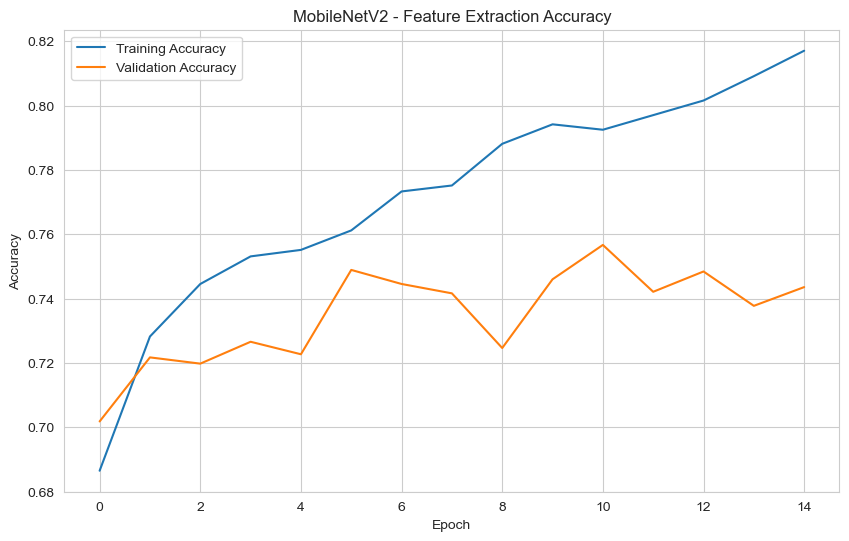

In [15]:
# Plot training and validation accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    history_head.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_head.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 - Feature Extraction Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

## Fine-Tuning

After training the classification head, we unfreeze
selected upper layers of MobileNetV2.

Fine-tuning allows the pretrained feature extractor
to adapt to skin lesion images.

A lower learning rate is used to avoid large changes
to pretrained weights.

BatchNormalization layers remain frozen for stability.

In [17]:
# Enable fine-tuning of the base model

base_model.trainable = True

# Freeze earlier layers and fine-tune the final layers

fine_tune_at = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen

for layer in base_model.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

print("Total layers:", len(base_model.layers))

print(
    "Trainable layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Total layers: 154
Trainable layers: 31


In [18]:
# Recompile after changing trainable layers

transfer_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [19]:
# Define fine-tuning checkpoint

FINE_TUNE_MODEL_PATH = MODEL_DIR / "mobilenetv2_finetuned_best.keras"

checkpoint_fine = ModelCheckpoint(
    filepath=str(FINE_TUNE_MODEL_PATH),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_fine = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_fine = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

fine_callbacks = [
    checkpoint_fine,
    early_stopping_fine,
    reduce_lr_fine
]

print("Fine-tuning callbacks configured!")

Fine-tuning callbacks configured!


In [20]:
# Continue training with selected pretrained layers unfrozen

history_fine = transfer_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=fine_callbacks,
    verbose=1
)

Epoch 1/15
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 862ms/step - accuracy: 0.7977 - loss: 0.5534
Epoch 1: val_loss improved from None to 0.71526, saving model to ..\models\mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to ..\models\mobilenetv2_finetuned_best.keras
186/186 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.7977 - loss: 0.5534 - val_accuracy: 0.7557 - val_loss: 0.7153 - learning_rate: 1.0000e-05
Epoch 2/15
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 859ms/step - accuracy: 0.8083 - loss: 0.5289
Epoch 2: val_loss did not improve from 0.71526
186/186 ━━━━━━━━━━━━━━━━━━━━ 198s 1s/step - accuracy: 0.8083 - loss: 0.5289 - val_accuracy: 0.7407 - val_loss: 0.7325 - learning_rate: 1.0000e-05
Epoch 3/15
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 875ms/step - accuracy: 0.8112 - loss: 0.5066
Epoch 3: val_loss did not improve from 0.71526

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
186/186 ━━━━━━━━━━━━━━━━━━━━ 198s 1s/step - accuracy: 0.8112 - loss: 0.5066 - val_accur

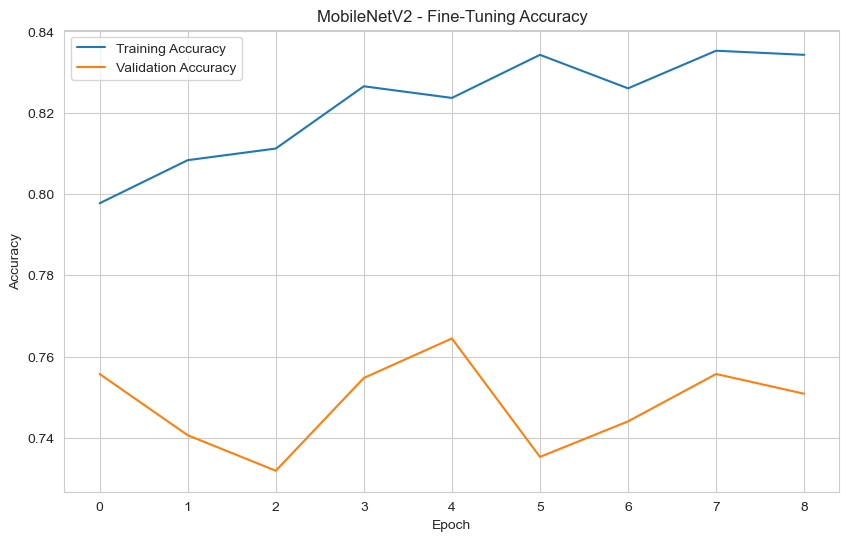

In [21]:
# Plot fine-tuning accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    history_fine.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_fine.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 - Fine-Tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

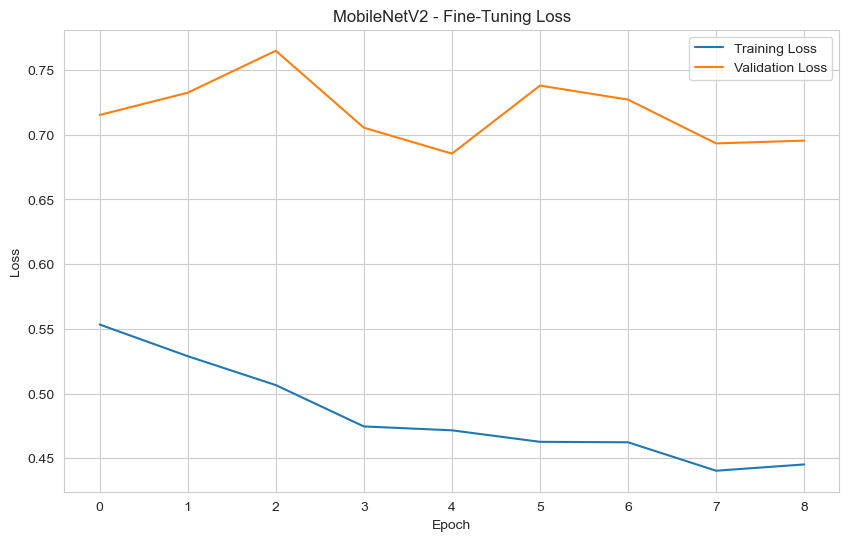

In [22]:
# Plot fine-tuning loss

plt.figure(figsize=(10, 6))

plt.plot(
    history_fine.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_fine.history["val_loss"],
    label="Validation Loss"
)

plt.title("MobileNetV2 - Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Save the final model after fine-tuning

FINAL_MODEL_PATH = MODEL_DIR / "skin_lesion_mobilenetv2.keras"

transfer_model.save(FINAL_MODEL_PATH)

print("Fine-tuned model saved at:", FINAL_MODEL_PATH)

In [23]:
# Save feature extraction history

pd.DataFrame(history_head.history).to_csv(
    OUTPUT_DIR / "mobilenetv2_training_history.csv",
    index=False
)

# Save fine-tuning history

pd.DataFrame(history_fine.history).to_csv(
    OUTPUT_DIR / "mobilenetv2_finetuning_history.csv",
    index=False
)

print("Both training histories saved successfully!")

Both training histories saved successfully!


## Conclusion

Transfer learning was performed using MobileNetV2
pretrained on ImageNet.

The classification head was trained first while
the pretrained base layers were frozen.

Selected upper layers were then unfrozen for
fine-tuning using a lower learning rate.

Training and validation performance were visualized.

The fine-tuned model was saved for evaluation.

Next Notebook:
05 - Model Evaluation and Performance Analysis